# FL-PERF-002.4 — Benchmark with 100 and 500 virtual clients

*Epic EPIC-001 · story fl_perf_002 · all results below are loaded from files produced by the task's experiment function and labelled MEASURED/SIMULATED; clients are virtual; data is synthetic.*

## 1. Research objective
Measure overhead at 100 and 500 virtual clients.

## 2. Scientific background
Performance of privacy-preserving FL is dominated by cryptographic computation and ciphertext/mask expansion [kairouz2021, li2020challenges]. All clients here are virtual and share one machine, so wall time includes serial execution of clients.

References use keys of `docs/references/references_master.md` (status per entry).

## 3. Research questions
- **RQ1.** What are the training-time, communication, memory and CPU overheads of each secure aggregation mechanism?
- **RQ2.** Are the story KPIs (<30% training overhead, <40% communication overhead, <1 pp accuracy loss) met?

## 4. Hypotheses
- **H1.** Secure aggregation overhead exceeds the 30%/40% KPIs for at least some mechanisms in simulation.

## 5. Mathematical formulation
overhead% = 100(x_secure − x_plain)/x_plain; throughput = samples processed / client compute seconds; scaling exponent b from log-log fit time ∝ n^b.

## 6. Experimental environment

In [1]:
import os, sys, json, platform, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
def _find_root():
    p = Path(os.environ.get("FL_ROOT") or os.environ.get("RS_ROOT") or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "src" / "federated_learning").exists():
            return q
    raise RuntimeError("repository root not found; set RS_ROOT")
ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
STORY = "fl_perf_002"
_cands = [ROOT / "experiments" / "results" / STORY]
RES = next(c for c in _cands if c.exists())
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED = 0; np.random.seed(SEED)
def show_csv(name, n=12):
    p = RES / name
    if p.exists(): display(pd.read_csv(p).round(4).head(n))
    else: print("MISSING", name)
def show_fig(name):
    for base in (RES / "figures", RES):
        if (base / name).exists(): display(Image(filename=str(base / name))); return
    print("MISSING figure", name)
print("root:", ROOT, "| results:", RES)

root: /home/claude/fl_sprint | results: /home/claude/fl_sprint/experiments/results/fl_perf_002


In [2]:
import importlib.metadata as md
vers = {}
for p in ["numpy","scipy","scikit-learn","torch","tenseal","phe","pandas","matplotlib","cryptography","psutil","mlflow","opacus"]:
    try: vers[p] = md.version(p)
    except Exception: vers[p] = "not installed"
print(json.dumps(dict(python=platform.python_version(), platform=platform.platform(), versions=vers, seed=SEED, gpu="none (CPU only; GPU metrics NOT_MEASURED)"), indent=1))

{
 "python": "3.13.18",
 "platform": "Linux-6.18.44-fc-v338-x86_64-with-glibc2.39",
 "versions": {
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "torch": "2.15.0",
  "tenseal": "0.3.18",
  "phe": "1.5.0",
  "pandas": "3.0.5",
  "matplotlib": "3.11.2",
  "cryptography": "50.0.1",
  "psutil": "7.2.2",
  "mlflow": "3.18.0",
  "opacus": "1.6.0"
 },
 "seed": 0,
 "gpu": "none (CPU only; GPU metrics NOT_MEASURED)"
}


## 7. Dataset description
Synthetic binary tabular dataset **SYN-IDS-v1** (scikit-learn `make_classification`, 40 features, 70:30 split). Chosen because no real IDS/clinical dataset was available in the sandbox. It has no clinical meaning; conclusions about absolute accuracy do not transfer.

In [3]:
from federated_learning.synthetic_data.generators.syn_ids_v1 import make_dataset, DATASET_ID
from federated_learning.data_partitioning.iid import partition_iid
from federated_learning.data_partitioning.dirichlet import partition_dirichlet
from federated_learning.data_partitioning.metrics import label_skew_stat
data = make_dataset(n_samples=6000, seed=SEED)
print(DATASET_ID, "train", data.X_train.shape, "test", data.X_test.shape, "positive rate", float(data.y_train.mean()))
print("NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.")

SYN-IDS-v1 train (4200, 40) test (1800, 40) positive rate 0.40095238095238095
NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.


## 8. Configuration and reproducibility settings
Seeds are fixed; each stored result carries `provenance` (experiment id, SHA-256 of the configuration, environment versions; `git_commit` is `null` because the workspace is not a git repository).

In [4]:
from federated_learning.training.config import FLConfig
cfg = FLConfig(rounds=5, local_epochs=1, seed=SEED)
print(cfg)

FLConfig(algo='fedavg', rounds=5, local_epochs=1, lr=0.05, batch_size=32, participation=1.0, mu=0.0, hidden=32, act='relu', seed=0, hetero_epochs=False, eval_every=1, server_lr=1.0)


## 9. Data preparation
Partitioning into virtual clients (IID or Dirichlet label skew) is performed by `federated_learning.data_partitioning`.

In [5]:
parts_iid = partition_iid(data.y_train, 10, SEED)
parts_dir = partition_dirichlet(data.y_train, 10, 0.3, SEED)
print('label-skew statistic IID:', round(label_skew_stat(data.y_train, parts_iid),3), ' Dirichlet(0.3):', round(label_skew_stat(data.y_train, parts_dir),3))

label-skew statistic IID: 0.019  Dirichlet(0.3): 0.363


## 10. Implementation
Reusable code lives in `src/federated_learning/` (`monitoring.py`, `fl.py`, `crypto/*`). The cell below exercises it live (small, fast, deterministic) and asserts correctness.

In [6]:
from federated_learning.training.config import FLConfig
from federated_learning.servers.orchestrator import run_fl
from federated_learning.monitoring.resources import ResourceMonitor
parts = partition_iid(data.y_train, 5, SEED)
with ResourceMonitor(0.02) as m:
    r = run_fl(FLConfig(rounds=3, local_epochs=1, seed=SEED), data, parts)
s = m.summary(); print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in s.items()})
assert s["cpu_time_s"] > 0 and s["wall_s"] > 0

{'wall_s': 0.138, 'cpu_time_s': 0.14, 'cpu_util_mean_pct': 105.917, 'cpu_util_peak_pct': 146.6, 'rss_mean_mb': 740.245, 'rss_peak_mb': 741.852, 'n_samples': 6, 'sample_interval_s': 0.02, 'gpu_available': False, 'gpu_util_pct': None, 'gpu_mem_mb': None}


## 11. Experiment execution
The full experiment was executed by `python -m federated_learning.pipelines.experiments.run_all --task FL-PERF-002.4` (see `logs/`). Its raw per-run results are loaded here; they are not re-computed inside the notebook.

In [7]:
show_csv('fl_perf_002.4a_runs.csv')
show_csv('fl_perf_002.4b_runs.csv')

,config,n_clients,seed,rounds,status,acc,f1,train_wall_s,client_time_s,agg_time_s,mean_round_s,up_mb,down_mb,comm_mb_per_round,throughput_samples_per_s,cpu_time_s,cpu_util_mean_pct,cpu_util_peak_pct,rss_mean_mb,rss_peak_mb,gpu_available,max_client_round_s,mlflow_run_id,train_overhead_pct,comm_overhead_pct,uplink_overhead_pct,acc_loss_pp
0,plain,100,0,10,ok,0.6142,0.2784,1.7967,1.7743,0.0079,0.1797,5.2567,5.2567,1.0513,47342.8173,1.76,97.4371,118.4,1006.8943,1006.8945,False,0.0070,7529bc33656740ed8ed53eb9e7c89e52,NaN,NaN,NaN,NaN
1,plain,100,1,10,ok,0.6286,0.2753,1.8887,1.8609,0.0089,0.1889,5.2567,5.2567,1.0513,45139.9854,1.87,98.6892,118.2,1006.8943,1006.8945,False,0.0041,d705e158c0ab41d5a58eefba60c3a0e3,NaN,NaN,NaN,NaN
2,secagg_complete,100,0,10,ok,0.6142,0.2784,40.0657,1.8617,38.1855,4.0066,32.9285,27.1606,6.0089,45121.2403,39.92,100.1930,193.0,1010.0139,1010.2344,False,0.0083,e0de6453704b46fd8155db866f797c4e,2129.9510,471.5530,526.4151,0.0
3,secagg_complete,100,1,10,ok,0.6286,0.2753,39.0989,1.9594,37.1241,3.9099,32.9285,27.1606,6.0089,42871.0433,38.90,100.3758,204.2,1010.2344,1010.2344,False,0.0059,1f6c9be610514421b2e19db040c14f21,1970.1769,471.5530,526.4151,0.0
4,secagg_sparse14,100,0,10,ok,0.6142,0.2784,5.5762,1.5985,3.9637,0.5576,13.7978,8.3542,2.2152,52549.7078,5.54,99.8083,137.7,1010.2343,1010.2344,False,0.0036,fd0bd822d04140fe99431a468195655b,210.3561,110.7039,162.4819,0.0
5,secagg_sparse14,100,1,10,ok,0.6286,0.2753,7.0925,2.0275,5.0450,0.7093,13.7978,8.3542,2.2152,41429.3796,7.09,100.2678,126.7,1010.2343,1010.2344,False,0.0043,939e9f1274ec470c939d907942e040ff,275.5281,110.7039,162.4819,0.0
6,he_ckks,100,0,10,ok,0.6142,0.2784,12.4426,1.8669,10.5600,1.2443,315.9334,5.2567,32.1190,44994.9912,12.35,99.7756,148.9,1023.9233,1025.1484,False,0.0055,65a8cf08625848e9966d516e8d0e104f,592.5248,2955.0816,5910.1633,0.0
7,he_ckks,100,1,10,ok,0.6286,0.2753,12.2364,1.8999,10.3113,1.2236,316.0666,5.2567,32.1323,44212.5032,12.12,99.5109,140.5,1026.9719,1027.6719,False,0.0067,7734403e4cab453ab4029fa508d1f2ef,547.8799,2956.3480,5912.6959,0.0
8,smpc_3party,100,0,10,ok,0.6142,0.2784,19.5045,1.9729,17.5134,1.9504,31.5399,5.2567,3.6797,42577.3500,19.31,99.0085,125.6,1027.6484,1027.6484,False,0.0231,cb5140449abe4c7c9af396e764b2d33a,985.5687,250.0000,500.0000,0.0
9,smpc_3party,100,1,10,ok,0.6286,0.2753,19.6455,1.9713,17.6588,1.9645,31.5399,5.2567,3.6797,42612.0657,19.57,99.7120,132.5,1027.6484,1027.6484,False,0.0055,30dd6d94fe484659b8f565f6ee5d80dd,940.1711,250.0000,500.0000,0.0


,config,n_clients,seed,rounds,status,acc,f1,train_wall_s,client_time_s,agg_time_s,mean_round_s,up_mb,down_mb,comm_mb_per_round,throughput_samples_per_s,cpu_time_s,cpu_util_mean_pct,cpu_util_peak_pct,rss_mean_mb,rss_peak_mb,gpu_available,max_client_round_s,mlflow_run_id,train_overhead_pct,comm_overhead_pct,uplink_overhead_pct,acc_loss_pp
0,plain,500,0,10,ok,0.535,0.4236,3.9800,3.9082,0.0387,0.3980,26.2833,26.2833,5.2567,21493.3536,3.91,97.9923,118.9,1027.6483,1027.6484,False,0.0203,082970ddac524576b17aec431b597b46,NaN,NaN,NaN,NaN
1,secagg_sparse14,500,0,10,ok,0.535,0.4236,27.2657,4.2120,23.0236,2.7266,68.9888,41.7709,11.0760,19943.0743,27.11,100.4143,355.8,1027.6484,1027.6484,False,0.1001,d1fd991d3190429fb97c8b699ee95283,585.0599,110.7039,162.4819,0.0
2,he_ckks,500,0,10,ok,0.535,0.4236,56.7382,3.8267,52.8817,5.6738,1580.3795,26.2833,160.6663,21951.1190,56.13,99.7023,143.7,1148.4073,1157.2891,False,0.0058,9b5b7f47635444cb8934dfa4b7490eb4,1325.5695,2956.4369,5912.8737,0.0
3,smpc_3party,500,0,10,ok,0.535,0.4236,86.5460,3.7235,82.7902,8.6546,157.6996,26.2833,18.3983,22559.6199,85.68,99.1302,138.7,1157.2691,1157.2773,False,0.0073,a30b88d5baac4fae90b049cbb53bdbda,2074.5006,250.0000,500.0000,0.0


## 12. Metrics collection
Metric definitions: Defined in `monitoring.py` docstring and docs/fl_perf_002/metrics_definitions.md: cpu_time_s (cumulative), cpu util mean/peak, RSS mean/peak, logical comm bytes, GPU = unavailable (never estimated).

In [8]:
show_csv('fl_perf_002.4a_runs.csv')

,config,n_clients,seed,rounds,status,acc,f1,train_wall_s,client_time_s,agg_time_s,mean_round_s,up_mb,down_mb,comm_mb_per_round,throughput_samples_per_s,cpu_time_s,cpu_util_mean_pct,cpu_util_peak_pct,rss_mean_mb,rss_peak_mb,gpu_available,max_client_round_s,mlflow_run_id,train_overhead_pct,comm_overhead_pct,uplink_overhead_pct,acc_loss_pp
0,plain,100,0,10,ok,0.6142,0.2784,1.7967,1.7743,0.0079,0.1797,5.2567,5.2567,1.0513,47342.8173,1.76,97.4371,118.4,1006.8943,1006.8945,False,0.0070,7529bc33656740ed8ed53eb9e7c89e52,NaN,NaN,NaN,NaN
1,plain,100,1,10,ok,0.6286,0.2753,1.8887,1.8609,0.0089,0.1889,5.2567,5.2567,1.0513,45139.9854,1.87,98.6892,118.2,1006.8943,1006.8945,False,0.0041,d705e158c0ab41d5a58eefba60c3a0e3,NaN,NaN,NaN,NaN
2,secagg_complete,100,0,10,ok,0.6142,0.2784,40.0657,1.8617,38.1855,4.0066,32.9285,27.1606,6.0089,45121.2403,39.92,100.1930,193.0,1010.0139,1010.2344,False,0.0083,e0de6453704b46fd8155db866f797c4e,2129.9510,471.5530,526.4151,0.0
3,secagg_complete,100,1,10,ok,0.6286,0.2753,39.0989,1.9594,37.1241,3.9099,32.9285,27.1606,6.0089,42871.0433,38.90,100.3758,204.2,1010.2344,1010.2344,False,0.0059,1f6c9be610514421b2e19db040c14f21,1970.1769,471.5530,526.4151,0.0
4,secagg_sparse14,100,0,10,ok,0.6142,0.2784,5.5762,1.5985,3.9637,0.5576,13.7978,8.3542,2.2152,52549.7078,5.54,99.8083,137.7,1010.2343,1010.2344,False,0.0036,fd0bd822d04140fe99431a468195655b,210.3561,110.7039,162.4819,0.0
5,secagg_sparse14,100,1,10,ok,0.6286,0.2753,7.0925,2.0275,5.0450,0.7093,13.7978,8.3542,2.2152,41429.3796,7.09,100.2678,126.7,1010.2343,1010.2344,False,0.0043,939e9f1274ec470c939d907942e040ff,275.5281,110.7039,162.4819,0.0
6,he_ckks,100,0,10,ok,0.6142,0.2784,12.4426,1.8669,10.5600,1.2443,315.9334,5.2567,32.1190,44994.9912,12.35,99.7756,148.9,1023.9233,1025.1484,False,0.0055,65a8cf08625848e9966d516e8d0e104f,592.5248,2955.0816,5910.1633,0.0
7,he_ckks,100,1,10,ok,0.6286,0.2753,12.2364,1.8999,10.3113,1.2236,316.0666,5.2567,32.1323,44212.5032,12.12,99.5109,140.5,1026.9719,1027.6719,False,0.0067,7734403e4cab453ab4029fa508d1f2ef,547.8799,2956.3480,5912.6959,0.0
8,smpc_3party,100,0,10,ok,0.6142,0.2784,19.5045,1.9729,17.5134,1.9504,31.5399,5.2567,3.6797,42577.3500,19.31,99.0085,125.6,1027.6484,1027.6484,False,0.0231,cb5140449abe4c7c9af396e764b2d33a,985.5687,250.0000,500.0000,0.0
9,smpc_3party,100,1,10,ok,0.6286,0.2753,19.6455,1.9713,17.6588,1.9645,31.5399,5.2567,3.6797,42612.0657,19.57,99.7120,132.5,1027.6484,1027.6484,False,0.0055,30dd6d94fe484659b8f565f6ee5d80dd,940.1711,250.0000,500.0000,0.0


## 13. Statistical analysis
Repeated seeds per configuration; CIs from t-distribution/bootstrap; no significance claims beyond CIs.

In [9]:
show_csv('fl_perf_002.4b_runs.csv', 15)

,config,n_clients,seed,rounds,status,acc,f1,train_wall_s,client_time_s,agg_time_s,mean_round_s,up_mb,down_mb,comm_mb_per_round,throughput_samples_per_s,cpu_time_s,cpu_util_mean_pct,cpu_util_peak_pct,rss_mean_mb,rss_peak_mb,gpu_available,max_client_round_s,mlflow_run_id,train_overhead_pct,comm_overhead_pct,uplink_overhead_pct,acc_loss_pp
0,plain,500,0,10,ok,0.535,0.4236,3.9800,3.9082,0.0387,0.3980,26.2833,26.2833,5.2567,21493.3536,3.91,97.9923,118.9,1027.6483,1027.6484,False,0.0203,082970ddac524576b17aec431b597b46,NaN,NaN,NaN,NaN
1,secagg_sparse14,500,0,10,ok,0.535,0.4236,27.2657,4.2120,23.0236,2.7266,68.9888,41.7709,11.0760,19943.0743,27.11,100.4143,355.8,1027.6484,1027.6484,False,0.1001,d1fd991d3190429fb97c8b699ee95283,585.0599,110.7039,162.4819,0.0
2,he_ckks,500,0,10,ok,0.535,0.4236,56.7382,3.8267,52.8817,5.6738,1580.3795,26.2833,160.6663,21951.1190,56.13,99.7023,143.7,1148.4073,1157.2891,False,0.0058,9b5b7f47635444cb8934dfa4b7490eb4,1325.5695,2956.4369,5912.8737,0.0
3,smpc_3party,500,0,10,ok,0.535,0.4236,86.5460,3.7235,82.7902,8.6546,157.6996,26.2833,18.3983,22559.6199,85.68,99.1302,138.7,1157.2691,1157.2773,False,0.0073,a30b88d5baac4fae90b049cbb53bdbda,2074.5006,250.0000,500.0000,0.0


## 14. Visualizations

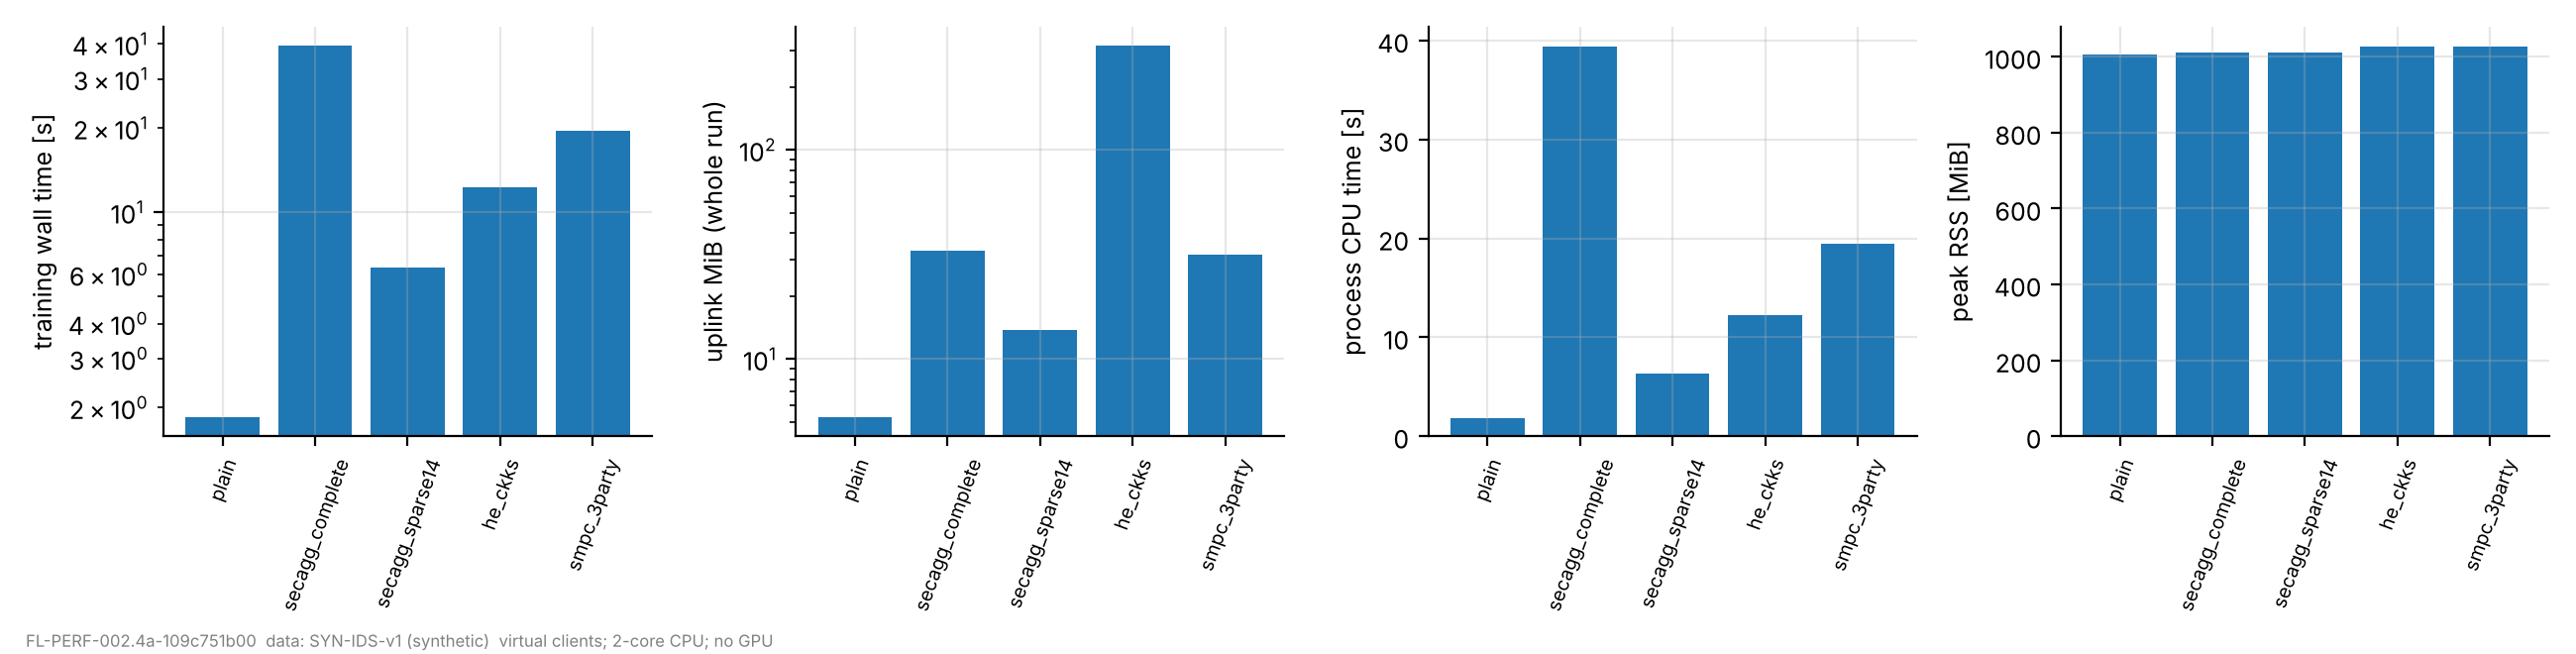

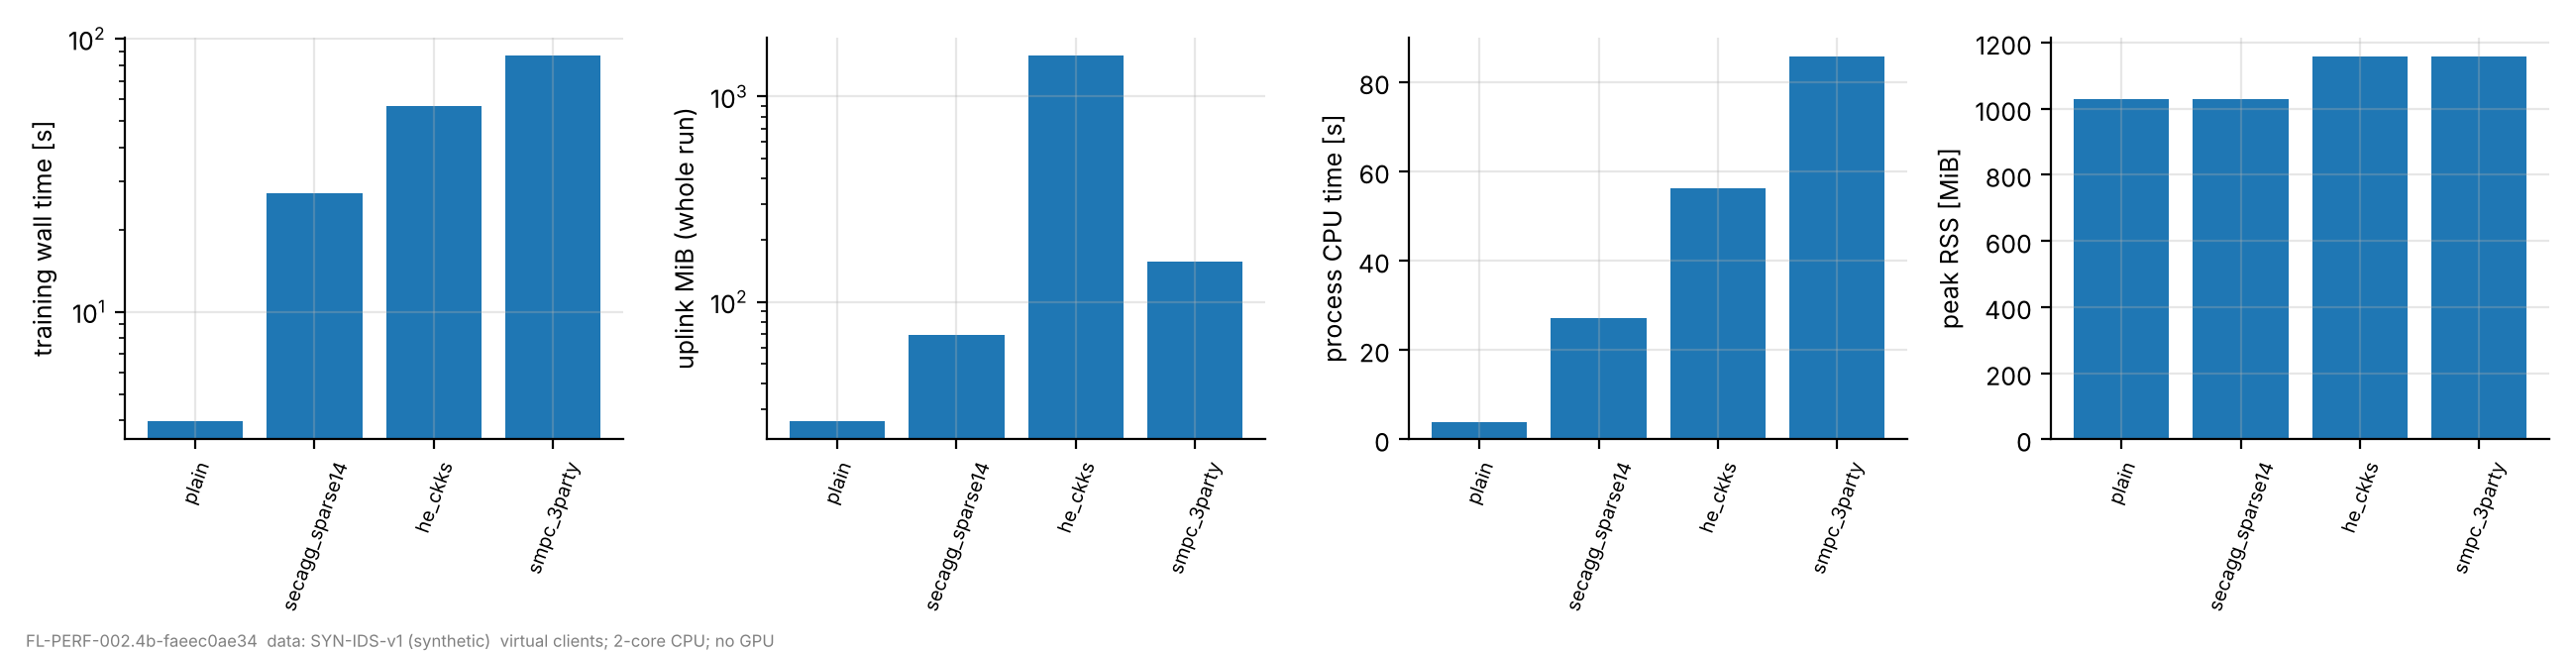

In [10]:
show_fig('task_2_4_benchmark_100.png')
show_fig('task_2_4_benchmark_500.png')

## 15. Interpretation of results
The numbers are computed in the next cell from the stored data; the text interprets only what that cell prints.

At 500 clients complete-graph SecAgg was NOT_RUN (cost); a sparse-graph variant (k=14) was measured instead.

In [11]:
print('see stored tables above; KPI verdicts are in task_2_5_kpi_check.csv (task 2.5)')

see stored tables above; KPI verdicts are in task_2_5_kpi_check.csv (task 2.5)


## 16. Limitations
- Virtual clients: time does not reflect parallel hospitals or network latency.
- Complete-graph SecAgg at 500 clients: NOT_RUN.
- Synthetic data, virtual clients on one machine, 2 CPU cores, no GPU; no real network. Comm. bytes are logical payload sizes.
- No regulatory/compliance conclusion can be drawn from this notebook.

## 17. Conclusions
See results_and_discussion.md for the KPI verdicts; they are reported as measured, including NOT MET.

**Jira acceptance:** see `docs/fl_perf_002/results_and_discussion.md` for the criterion-by-criterion verdict (MET / PARTIALLY MET / NOT MET).

## 18. References
`kairouz2021`, `li2020challenges`, `bonawitz2017`, `cheon2017` — details in `docs/fl_perf_002/references.md`.